In [1]:
from pathlib import Path

root = Path("/kaggle/input")
print("Input exists:", root.exists())

for dataset in sorted(root.iterdir()):
    print(f"\n{dataset.name}/")
    if dataset.is_dir():
        for item in sorted(dataset.iterdir())[:30]:
            if item.is_file():
                print(f"  {item.name} ({item.stat().st_size / 1e6:.1f} MB)")
            else:
                print(f"  {item.name}/")

Input exists: True

competitions/
  rsna-knee-abnormality-detection/


In [2]:
from pathlib import Path
from collections import Counter

data_root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
print("Competition folder exists:", data_root.exists())

if data_root.exists():
    for item in sorted(data_root.iterdir()):
        if item.is_file():
            print(f"FILE: {item.name} ({item.stat().st_size / 1e6:.1f} MB)")
        elif item.is_dir():
            children = list(item.iterdir())
            extensions = Counter(
                child.suffix.lower() or "<no extension>"
                for child in children if child.is_file()
            )
            print(
                f"FOLDER: {item.name}/ — "
                f"{len(children):,} immediate entries; "
                f"file extensions: {dict(extensions)}"
            )

Competition folder exists: True
FILE: sample_submission.csv (0.0 MB)
FILE: test.csv (0.0 MB)
FOLDER: test_series/ — 3 immediate entries; file extensions: {}
FILE: test_series.csv (0.0 MB)
FILE: train.csv (5.7 MB)
FOLDER: train_series/ — 4,407 immediate entries; file extensions: {}
FILE: train_series.csv (3.5 MB)


In [3]:
from pathlib import Path
from collections import Counter
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")

# Show CSV columns and basic metadata only—not row contents.
for csv_path in sorted(root.glob("*.csv")):
    frame = pd.read_csv(csv_path, nrows=1000)
    print(f"\n{csv_path.name}: {len(frame):,}+ rows sampled")
    print("Columns:", list(frame.columns))
    print("Dtypes:", {col: str(dtype) for col, dtype in frame.dtypes.items()})

# Show folder structure and file types, but not individual series filenames.
for folder_name in ("test_series", "train_series"):
    folder = root / folder_name
    print(f"\n{folder_name}: exists={folder.exists()}")
    if folder.is_dir():
        entries = list(folder.iterdir())
        print(f"  Immediate entries: {len(entries):,}")
        print("  Entry types:", dict(Counter(
            "folder" if p.is_dir() else (p.suffix.lower() or "no extension")
            for p in entries
        )))
        for subfolder in [p for p in entries if p.is_dir()][:5]:
            subentries = list(subfolder.iterdir())
            print(
                f"  Nested folder: {len(subentries):,} entries; "
                f"types={dict(Counter('folder' if p.is_dir() else (p.suffix.lower() or 'no extension') for p in subentries))}"
            )


sample_submission.csv: 3+ rows sampled
Columns: ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
Dtypes: {'StudyInstanceUID': 'object', 'ACL': 'float64', 'MCL': 'float64', 'Medial Meniscus': 'float64', 'Lateral Meniscus': 'float64', 'Medial OA': 'float64', 'Lateral OA': 'float64', 'PF OA': 'float64', 'Effusion': 'float64', 'Synovitis': 'float64', "Baker's": 'float64', 'Contusion': 'float64', 'Fracture': 'float64'}

test.csv: 3+ rows sampled
Columns: ['StudyInstanceUID']
Dtypes: {'StudyInstanceUID': 'object'}

test_series.csv: 15+ rows sampled
Columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']
Dtypes: {'StudyInstanceUID': 'object', 'SeriesInstanceUID': 'object', 'Fluid_Sensitive': 'int64', 'Fat_Suppression': 'int64', 'Anatomical_Plane': 'object'}

train.csv: 1,000+ rows sampled
Columns: ['StudyInstanceUID', '

In [4]:
from pathlib import Path
from collections import Counter
import os
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

# Full training-label summary; deliberately exclude the report column.
train = pd.read_csv(root / "train.csv", usecols=lambda c: c != "Report")
print("Training studies:", len(train))
print("Duplicate training study IDs:", train["StudyInstanceUID"].duplicated().sum())
print("\nLabels: positive count and missing count")
for col in targets:
    values = pd.to_numeric(train[col], errors="coerce")
    print(f"{col}: positives={int((values == 1).sum())}, missing={int(values.isna().sum())}")

# Series/plane metadata summary.
for split in ("train", "test"):
    series = pd.read_csv(root / f"{split}_series.csv")
    study_count = series["StudyInstanceUID"].nunique()
    print(f"\n{split} series rows: {len(series):,}; studies: {study_count:,}")
    print("Plane counts:", series["Anatomical_Plane"].value_counts(dropna=False).to_dict())
    print("Studies represented in the study list:", len(pd.read_csv(root / f"{split}.csv")))

# Walk the image folders and summarize file layout without showing IDs/filenames.
for split in ("train", "test"):
    folder = root / f"{split}_series"
    extensions = Counter()
    file_depths = Counter()
    safe_examples = []
    total_files = 0

    for current, _, filenames in os.walk(folder):
        for filename in filenames:
            total_files += 1
            suffix = Path(filename).suffix.lower() or "<no extension>"
            extensions[suffix] += 1
            depth = len(Path(current).relative_to(folder).parts) + 1
            file_depths[depth] += 1
            if len(safe_examples) < 3:
                safe_examples.append("/".join(
                    ["<folder>"] * depth + [f"<file>{suffix}"]
                ))

    print(f"\n{split}_series image files: {total_files:,}")
    print("File extensions:", dict(extensions))
    print("File path depths:", dict(sorted(file_depths.items())))
    print("Example path shapes (IDs hidden):", safe_examples)

Training studies: 4407
Duplicate training study IDs: 0

Labels: positive count and missing count
ACL: positives=24, missing=4349
MCL: positives=9, missing=4349
Medial Meniscus: positives=26, missing=4349
Lateral Meniscus: positives=23, missing=4349
Medial OA: positives=15, missing=4349
Lateral OA: positives=11, missing=4349
PF OA: positives=21, missing=4349
Effusion: positives=35, missing=4349
Synovitis: positives=27, missing=4349
Baker's: positives=12, missing=4349
Contusion: positives=19, missing=4349
Fracture: positives=18, missing=4349

train series rows: 24,371; studies: 4,407
Plane counts: {'Sagittal': 9864, 'Coronal': 8609, 'Axial': 5898}
Studies represented in the study list: 4407

test series rows: 15; studies: 3
Plane counts: {'Sagittal': 7, 'Axial': 4, 'Coronal': 4}
Studies represented in the study list: 3

train_series image files: 819,078
File extensions: {'.dcm': 819078}
File path depths: {3: 819078}
Example path shapes (IDs hidden): ['<folder>/<folder>/<folder>/<file>.dc

In [5]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

# Count observed labels without showing study IDs or report text.
train = pd.read_csv(root / "train.csv", usecols=lambda c: c != "Report")
observed = train[targets].notna()

print("Studies with at least one observed label:", int(observed.any(axis=1).sum()))
print("Studies with all 12 labels observed:", int(observed.all(axis=1).sum()))
print("Observed values per target:")
for col in targets:
    print(f"  {col}: {int(observed[col].sum())}")

# Show the folder depth and file type for a few image files; hide folder names.
train_dir = root / "train_series"
examples = []
for study_dir in sorted(train_dir.iterdir()):
    if not study_dir.is_dir():
        continue
    for series_dir in sorted(study_dir.iterdir()):
        if not series_dir.is_dir():
            continue
        for image_path in series_dir.rglob("*"):
            if image_path.is_file():
                examples.append(image_path)
                break
        if examples:
            break
    if len(examples) >= 3:
        break

print("\nExample image-file layouts (folder names hidden):")
for path in examples:
    relative = path.relative_to(train_dir)
    print(f"  {len(relative.parts)} path components; extension={path.suffix or '<none>'}")

if examples:
    try:
        import pydicom

        ds = pydicom.dcmread(examples[0], stop_before_pixels=True)
        print("\nFirst image header (safe fields only):")
        for name in (
            "Modality", "Rows", "Columns",
            "PixelSpacing", "SliceThickness", "ImageOrientationPatient",
        ):
            print(f"  {name}: {getattr(ds, name, None)}")
    except ImportError:
        print("\npydicom isn't available in this notebook session yet.")



Studies with at least one observed label: 58
Studies with all 12 labels observed: 58
Observed values per target:
  ACL: 58
  MCL: 58
  Medial Meniscus: 58
  Lateral Meniscus: 58
  Medial OA: 58
  Lateral OA: 58
  PF OA: 58
  Effusion: 58
  Synovitis: 58
  Baker's: 58
  Contusion: 58
  Fracture: 58

Example image-file layouts (folder names hidden):
  3 path components; extension=.dcm
  3 path components; extension=.dcm
  3 path components; extension=.dcm

First image header (safe fields only):
  Modality: MR
  Rows: 512
  Columns: 512
  PixelSpacing: [0.330078125, 0.330078125]
  SliceThickness: 3.4
  ImageOrientationPatient: [-0.0334932804107, 0.99921125173568, 0.02133215218782, 0.05801957845687, 0.02325204573571, -0.9980446100234]


In [6]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
train_dir = root / "train_series"

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

labels = pd.read_csv(root / "train.csv", usecols=lambda c: c != "Report")
labeled_ids = set(
    labels.loc[labels[targets].notna().all(axis=1), "StudyInstanceUID"]
)

series = pd.read_csv(root / "train_series.csv")
series = series[series["StudyInstanceUID"].isin(labeled_ids)].copy()

# The observed layout is study-folder / series-folder / DICOM-file.
# Match folder names internally; do not print the IDs.
rows = []
missing_series_folders = 0

for study_id in labeled_ids:
    study_folder = train_dir / study_id
    if not study_folder.is_dir():
        continue

    for series_folder in study_folder.iterdir():
        if not series_folder.is_dir():
            continue

        dicom_count = sum(
            1 for path in series_folder.iterdir()
            if path.is_file() and path.suffix.lower() == ".dcm"
        )
        if dicom_count:
            rows.append({
                "StudyInstanceUID": study_id,
                "SeriesInstanceUID": series_folder.name,
                "dicom_slices": dicom_count,
            })

paths = pd.DataFrame(rows)
if paths.empty:
    raise RuntimeError("No DICOM series folders found for the labeled studies.")

series_map = series.merge(
    paths,
    on=["StudyInstanceUID", "SeriesInstanceUID"],
    how="left",
    validate="one_to_one",
)
missing_series_folders = int(series_map["dicom_slices"].isna().sum())

print("Expert-labeled studies:", len(labeled_ids))
print("Series metadata rows for those studies:", len(series_map))
print("Series with matching DICOM folders:", int(series_map["dicom_slices"].notna().sum()))
print("Series missing a DICOM folder:", missing_series_folders)
print("\nSeries counts by plane:")
print(series_map.groupby("Anatomical_Plane").size().to_string())
print("\nDICOM slice-count summary by plane:")
print(series_map.groupby("Anatomical_Plane")["dicom_slices"].describe().round(1).to_string())
print("\nFluid-sensitive series by plane:")
print(
    series_map.groupby("Anatomical_Plane")["Fluid_Sensitive"]
    .agg(["count", "sum"])
    .to_string()
)

Expert-labeled studies: 58
Series metadata rows for those studies: 336
Series with matching DICOM folders: 336
Series missing a DICOM folder: 0

Series counts by plane:
Anatomical_Plane
Axial        81
Coronal     119
Sagittal    136

DICOM slice-count summary by plane:
                  count  mean   std   min   25%   50%   75%    max
Anatomical_Plane                                                  
Axial              81.0  34.6  20.4  12.0  28.0  32.0  40.0  160.0
Coronal           119.0  28.2   6.4  15.0  24.5  30.0  32.0   42.0
Sagittal          136.0  32.2  30.0  11.0  23.0  29.0  33.0  320.0

Fluid-sensitive series by plane:
                  count  sum
Anatomical_Plane            
Axial                81   63
Coronal             119   65
Sagittal            136   64


In [7]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
train_dir = root / "train_series"
targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
planes = ["Sagittal", "Coronal", "Axial"]

# Only use studies with all 12 expert labels; never convert missing labels to 0.
labels = pd.read_csv(root / "train.csv", usecols=lambda col: col != "Report")
labels = labels.loc[labels[targets].notna().all(axis=1)].copy()

series = pd.read_csv(root / "train_series.csv")
series = series[series["StudyInstanceUID"].isin(labels["StudyInstanceUID"])].copy()

# Count DICOM slices in each series folder and verify the folder mapping.
folder_rows = []
for row in series[["StudyInstanceUID", "SeriesInstanceUID"]].itertuples(index=False):
    series_folder = train_dir / row.StudyInstanceUID / row.SeriesInstanceUID
    if not series_folder.is_dir():
        continue
    slice_count = sum(
        1 for path in series_folder.iterdir()
        if path.is_file() and path.suffix.lower() == ".dcm"
    )
    if slice_count:
        folder_rows.append({
            "StudyInstanceUID": row.StudyInstanceUID,
            "SeriesInstanceUID": row.SeriesInstanceUID,
            "dicom_slices": slice_count,
            "series_path": str(series_folder),
        })

folder_index = pd.DataFrame(folder_rows)
series = series.merge(
    folder_index,
    on=["StudyInstanceUID", "SeriesInstanceUID"],
    how="inner",
    validate="one_to_one",
)

# Prefer fluid-sensitive series; within that choice, prefer the most slices.
series["Fluid_Sensitive"] = pd.to_numeric(
    series["Fluid_Sensitive"], errors="coerce"
).fillna(0)
series = series.sort_values(
    ["StudyInstanceUID", "Anatomical_Plane", "Fluid_Sensitive",
     "dicom_slices", "SeriesInstanceUID"],
    ascending=[True, True, False, False, True],
)
selected = series.drop_duplicates(
    ["StudyInstanceUID", "Anatomical_Plane"], keep="first"
)

# Build one row per expert-labeled study, with separate fields for each plane.
manifest = labels[["StudyInstanceUID", *targets]].copy()
for plane in planes:
    plane_rows = selected[selected["Anatomical_Plane"] == plane][
        ["StudyInstanceUID", "SeriesInstanceUID", "series_path",
         "dicom_slices", "Fluid_Sensitive"]
    ].rename(columns={
        "SeriesInstanceUID": f"{plane}_SeriesInstanceUID",
        "series_path": f"{plane}_Path",
        "dicom_slices": f"{plane}_Slices",
        "Fluid_Sensitive": f"{plane}_FluidSensitive",
    })
    manifest = manifest.merge(
        plane_rows, on="StudyInstanceUID", how="left", validate="one_to_one"
    )

manifest_path = Path("/kaggle/working/rsna_labeled_manifest.csv")
manifest.to_csv(manifest_path, index=False)

print("Expert-labeled studies:", len(manifest))
print("Manifest saved:", manifest_path)
for plane in planes:
    print(f"{plane} series available:", int(manifest[f"{plane}_Path"].notna().sum()))

print("\nPositive labels among the 58 expert-labeled studies:")
for target in targets:
    print(f"{target}: {int((manifest[target] == 1).sum())}")

print("\nSlice-count summary for selected series:")
print(manifest[[f"{plane}_Slices" for plane in planes]].describe().round(1))

Expert-labeled studies: 58
Manifest saved: /kaggle/working/rsna_labeled_manifest.csv
Sagittal series available: 58
Coronal series available: 58
Axial series available: 58

Positive labels among the 58 expert-labeled studies:
ACL: 24
MCL: 9
Medial Meniscus: 26
Lateral Meniscus: 23
Medial OA: 15
Lateral OA: 11
PF OA: 21
Effusion: 35
Synovitis: 27
Baker's: 12
Contusion: 19
Fracture: 18

Slice-count summary for selected series:
       Sagittal_Slices  Coronal_Slices  Axial_Slices
count             58.0            58.0          58.0
mean              33.6            28.8          36.4
std               38.8             6.2          23.2
min               15.0            15.0          15.0
25%               24.0            26.0          30.0
50%               29.0            30.0          32.0
75%               34.0            32.0          40.0
max              320.0            42.0         160.0


Sagittal: slices=36, shape=(320, 320), dtype=uint16, intensity_min=0.0, intensity_max=636.0
Coronal: slices=30, shape=(320, 320), dtype=uint16, intensity_min=0.0, intensity_max=641.0
Axial: slices=32, shape=(320, 320), dtype=uint16, intensity_min=0.0, intensity_max=650.0


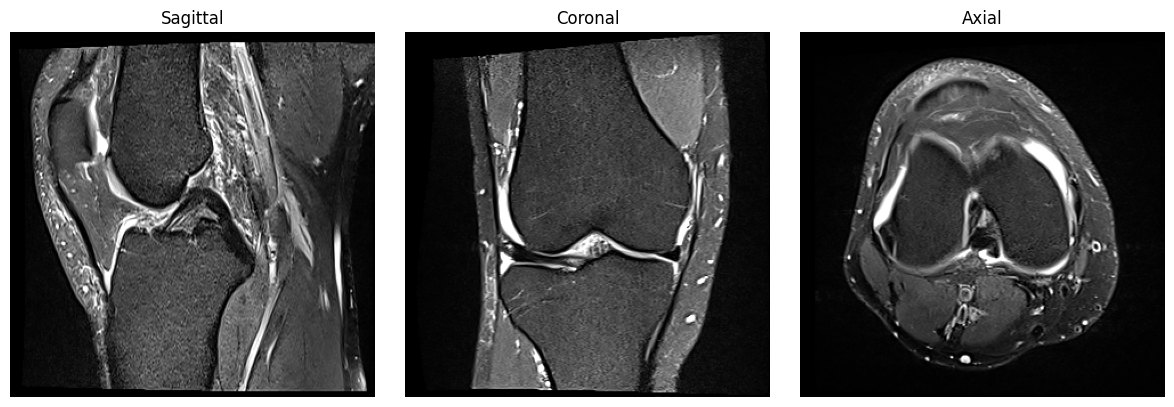

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt

manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")
sample = manifest.iloc[0]

planes = ["Sagittal", "Coronal", "Axial"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for plane, ax in zip(planes, axes):
    series_dir = Path(sample[f"{plane}_Path"])
    dicom_files = list(series_dir.glob("*.dcm"))

    if not dicom_files:
        raise FileNotFoundError(f"No DICOM files found for the {plane} series.")

    # Sort by DICOM InstanceNumber when available.
    ordered = []
    for path in dicom_files:
        ds = pydicom.dcmread(path, stop_before_pixels=True)
        instance_number = getattr(ds, "InstanceNumber", None)
        sort_key = int(instance_number) if instance_number is not None else path.name
        ordered.append((sort_key, path))
    ordered.sort(key=lambda item: item[0])

    # Read only the middle slice's pixels.
    middle_path = ordered[len(ordered) // 2][1]
    ds = pydicom.dcmread(middle_path)
    image = ds.pixel_array.astype(np.float32)

    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        image = image.max() - image

    low, high = np.percentile(image, [1, 99])
    if high <= low:
        raise ValueError(f"The {plane} slice has no usable intensity range.")

    display_image = np.clip((image - low) / (high - low), 0, 1)

    print(
        f"{plane}: slices={len(dicom_files)}, "
        f"shape={image.shape}, dtype={ds.pixel_array.dtype}, "
        f"intensity_min={image.min():.1f}, intensity_max={image.max():.1f}"
    )

    ax.imshow(display_image, cmap="gray")
    ax.set_title(plane)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import pydicom
from PIL import Image

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
planes = ["Sagittal", "Coronal", "Axial"]
image_size = 224

# Verify all included studies have the full set of expert labels.
if manifest[targets].isna().any().any():
    raise ValueError("Manifest contains missing labels; do not replace them with zero.")

images = np.zeros(
    (len(manifest), len(planes), image_size, image_size),
    dtype=np.float32,
)
labels = manifest[targets].to_numpy(dtype=np.float32)

for study_index, row in enumerate(manifest.itertuples(index=False)):
    for plane_index, plane in enumerate(planes):
        series_dir = Path(getattr(row, f"{plane}_Path"))
        dicom_paths = list(series_dir.glob("*.dcm"))
        if not dicom_paths:
            raise FileNotFoundError(f"No DICOM slices found for the {plane} series.")

        # Choose the middle slice by DICOM InstanceNumber.
        slices = []
        for path in dicom_paths:
            header = pydicom.dcmread(path, stop_before_pixels=True)
            instance_number = getattr(header, "InstanceNumber", None)
            if instance_number is None:
                raise ValueError(f"Missing InstanceNumber in a {plane} series slice.")
            slices.append((int(instance_number), path))

        slices.sort(key=lambda entry: entry[0])
        middle_path = slices[len(slices) // 2][1]
        ds = pydicom.dcmread(middle_path)

        pixels = ds.pixel_array.astype(np.float32)
        pixels = pixels * float(getattr(ds, "RescaleSlope", 1.0))
        pixels += float(getattr(ds, "RescaleIntercept", 0.0))

        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            pixels = pixels.max() - pixels

        low, high = np.percentile(pixels, [1, 99])
        if not np.isfinite(low) or not np.isfinite(high) or high <= low:
            raise ValueError(f"Invalid intensity range for the {plane} slice.")

        normalized = np.clip((pixels - low) / (high - low), 0, 1)
        resized = Image.fromarray((normalized * 255).astype(np.uint8)).resize(
            (image_size, image_size),
            resample=Image.Resampling.BILINEAR,
        )
        images[study_index, plane_index] = np.asarray(resized, dtype=np.float32) / 255.0

    if (study_index + 1) % 10 == 0 or study_index + 1 == len(manifest):
        print(f"Processed studies: {study_index + 1}/{len(manifest)}")

cache_path = Path("/kaggle/working/rsna_expert_pilot_224.npz")
np.savez_compressed(cache_path, images=images, labels=labels)

# Verify the saved cache and its numeric ranges.
with np.load(cache_path) as cache:
    saved_images = cache["images"]
    saved_labels = cache["labels"]
    print("\nCache:", cache_path)
    print("Images shape:", saved_images.shape)
    print("Labels shape:", saved_labels.shape)
    print("Image range:", float(saved_images.min()), "to", float(saved_images.max()))
    print("All image values finite:", bool(np.isfinite(saved_images).all()))
    print("All labels finite:", bool(np.isfinite(saved_labels).all()))

Processed studies: 10/58
Processed studies: 20/58
Processed studies: 30/58
Processed studies: 40/58
Processed studies: 50/58
Processed studies: 58/58

Cache: /kaggle/working/rsna_expert_pilot_224.npz
Images shape: (58, 3, 224, 224)
Labels shape: (58, 12)
Image range: 0.0 to 1.0
All image values finite: True
All labels finite: True


In [10]:
import numpy as np
import pandas as pd
from pathlib import Path

manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")
targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

if manifest[targets].isna().any().any():
    raise ValueError("Missing labels found; do not replace them with zero.")

y = manifest[targets].to_numpy(dtype=np.int8)
n_studies = len(y)
n_val = int(round(n_studies * 0.2))
rng = np.random.default_rng(42)

# Search for a deterministic split where both sets contain positives and
# negatives for every target, preferring validation counts near 20% of each.
best = None
best_score = float("inf")

for _ in range(20_000):
    val_idx = rng.choice(n_studies, size=n_val, replace=False)
    train_mask = np.ones(n_studies, dtype=bool)
    train_mask[val_idx] = False

    train_pos = y[train_mask].sum(axis=0)
    val_pos = y[val_idx].sum(axis=0)

    if np.any(train_pos == 0) or np.any(train_pos == train_mask.sum()):
        continue
    if np.any(val_pos == 0) or np.any(val_pos == n_val):
        continue

    expected_val_pos = y.sum(axis=0) * (n_val / n_studies)
    score = float(np.abs(val_pos - expected_val_pos).sum())

    if score < best_score:
        best = (train_mask, val_idx)
        best_score = score

if best is None:
    raise RuntimeError(
        "Could not find a split with both classes for every label in both sets. "
        "Use grouped cross-validation or revise the validation strategy."
    )

train_mask, val_idx = best
split = np.full(n_studies, "train", dtype=object)
split[val_idx] = "validation"

split_path = Path("/kaggle/working/rsna_expert_split.csv")
pd.DataFrame({
    "StudyInstanceUID": manifest["StudyInstanceUID"],
    "split": split,
}).to_csv(split_path, index=False)

print(f"Train studies: {int(train_mask.sum())}")
print(f"Validation studies: {len(val_idx)}")
print(f"Split saved: {split_path}")
print("\nPositive / negative counts by split:")
for i, target in enumerate(targets):
    train_pos = int(y[train_mask, i].sum())
    val_pos = int(y[val_idx, i].sum())
    print(
        f"{target}: train {train_pos}/{int(train_mask.sum()) - train_pos} "
        f"positive/negative; validation {val_pos}/{len(val_idx) - val_pos}"
    )

Train studies: 46
Validation studies: 12
Split saved: /kaggle/working/rsna_expert_split.csv

Positive / negative counts by split:
ACL: train 19/27 positive/negative; validation 5/7
MCL: train 7/39 positive/negative; validation 2/10
Medial Meniscus: train 21/25 positive/negative; validation 5/7
Lateral Meniscus: train 19/27 positive/negative; validation 4/8
Medial OA: train 12/34 positive/negative; validation 3/9
Lateral OA: train 9/37 positive/negative; validation 2/10
PF OA: train 17/29 positive/negative; validation 4/8
Effusion: train 28/18 positive/negative; validation 7/5
Synovitis: train 21/25 positive/negative; validation 6/6
Baker's: train 9/37 positive/negative; validation 3/9
Contusion: train 15/31 positive/negative; validation 4/8
Fracture: train 14/32 positive/negative; validation 4/8


In [11]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score, roc_auc_score

# Reproducibility for this pilot run.
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")
split_df = pd.read_csv("/kaggle/working/rsna_expert_split.csv")

with np.load("/kaggle/working/rsna_expert_pilot_224.npz") as cache:
    images = cache["images"].astype(np.float32)
    labels = cache["labels"].astype(np.float32)

# Ensure cached images, labels, manifest, and split use the same study order.
if len(manifest) != len(images) or len(manifest) != len(labels):
    raise ValueError("Cache and manifest row counts do not match.")
if not np.array_equal(
    manifest["StudyInstanceUID"].to_numpy(),
    split_df["StudyInstanceUID"].to_numpy(),
):
    raise ValueError("Manifest and split study order differs; align by study ID first.")
if labels.shape[1] != len(targets) or not np.isfinite(labels).all():
    raise ValueError("Labels have an unexpected shape or contain non-finite values.")

train_mask = split_df["split"].eq("train").to_numpy()
val_mask = split_df["split"].eq("validation").to_numpy()
if train_mask.sum() == 0 or val_mask.sum() == 0:
    raise ValueError("The train/validation split is empty.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Train studies:", int(train_mask.sum()))
print("Validation studies:", int(val_mask.sum()))

x_train = torch.from_numpy(images[train_mask])
y_train = torch.from_numpy(labels[train_mask])
x_val = torch.from_numpy(images[val_mask]).to(device)
y_val = torch.from_numpy(labels[val_mask]).to(device)

# Class weighting uses training labels only; cap weights to limit instability
# from the very small number of expert-labeled studies.
positive = y_train.sum(dim=0)
negative = len(y_train) - positive
if torch.any(positive == 0) or torch.any(negative == 0):
    raise ValueError("A training label has only one class; cannot train this baseline.")
pos_weight = (negative / positive).clamp(min=1.0, max=5.0).to(device)

train_loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=8,
    shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)

class SmallMultiPlaneCNN(nn.Module):
    def __init__(self, number_of_labels: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(4, 32),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, number_of_labels),
        )

    def forward(self, x):
        return self.features(x)

model = SmallMultiPlaneCNN(len(targets)).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

best_val_loss = float("inf")
best_state = None
patience = 4
epochs_without_improvement = 0
max_epochs = 15

for epoch in range(1, max_epochs + 1):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(batch_x)
        train_count += len(batch_x)

    model.eval()
    with torch.no_grad():
        val_logits = model(x_val)
        val_loss = criterion(val_logits, y_val).item()

    train_loss = train_loss_sum / train_count
    print(
        f"Epoch {epoch:02d}: "
        f"train_loss={train_loss:.4f}, val_loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping: validation loss did not improve.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model(x_val)).cpu().numpy()

results = []
for index, target in enumerate(targets):
    truth = labels[val_mask, index]
    results.append({
        "label": target,
        "positive_validation_cases": int(truth.sum()),
        "roc_auc": roc_auc_score(truth, probabilities[:, index]),
        "average_precision": average_precision_score(truth, probabilities[:, index]),
    })

results_df = pd.DataFrame(results)
print("\nPreliminary validation metrics:")
print(results_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(
    "\nMacro ROC AUC:",
    f"{results_df['roc_auc'].mean():.3f}",
    "| Macro average precision:",
    f"{results_df['average_precision'].mean():.3f}",
)

checkpoint_path = Path("/kaggle/working/rsna_pilot_cnn.pt")
torch.save(model.state_dict(), checkpoint_path)
print("\nPilot checkpoint saved:", checkpoint_path)
print("Reminder: these 12-study validation metrics are highly uncertain.")

Device: cpu
Train studies: 46
Validation studies: 12
Epoch 01: train_loss=0.9415, val_loss=0.9247
Epoch 02: train_loss=0.9165, val_loss=0.9216
Epoch 03: train_loss=0.9200, val_loss=0.9218
Epoch 04: train_loss=0.9072, val_loss=0.9231
Epoch 05: train_loss=0.9075, val_loss=0.9244
Epoch 06: train_loss=0.9109, val_loss=0.9247
Early stopping: validation loss did not improve.

Preliminary validation metrics:
           label  positive_validation_cases  roc_auc  average_precision
             ACL                          5    0.429              0.405
             MCL                          2    0.500              0.236
 Medial Meniscus                          5    0.429              0.432
Lateral Meniscus                          4    0.688              0.483
       Medial OA                          3    0.370              0.261
      Lateral OA                          2    0.400              0.200
           PF OA                          4    0.469              0.368
        Effusion   

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
from PIL import Image

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
train_dir = root / "train_series"

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
planes = ["Sagittal", "Coronal", "Axial"]
slices_per_plane = 8
image_size = 224

# Rebuild labels and manifest from persistent competition inputs.
labels = pd.read_csv(root / "train.csv", usecols=lambda col: col != "Report")
labels = labels.loc[labels[targets].notna().all(axis=1)].copy()
if labels.empty:
    raise ValueError("No fully labeled expert studies found in train.csv.")

series = pd.read_csv(root / "train_series.csv")
series = series[series["StudyInstanceUID"].isin(labels["StudyInstanceUID"])].copy()

folder_rows = []
for _, row in series.iterrows():
    series_dir = train_dir / str(row["StudyInstanceUID"]) / str(row["SeriesInstanceUID"])
    if not series_dir.is_dir():
        continue

    dicom_count = sum(
        1 for path in series_dir.iterdir()
        if path.is_file() and path.suffix.lower() == ".dcm"
    )
    if dicom_count:
        folder_rows.append({
            "StudyInstanceUID": row["StudyInstanceUID"],
            "SeriesInstanceUID": row["SeriesInstanceUID"],
            "series_path": str(series_dir),
            "dicom_slices": dicom_count,
        })

folder_index = pd.DataFrame(folder_rows)
if folder_index.empty:
    raise FileNotFoundError("No DICOM series folders matched train_series.csv.")

series = series.merge(
    folder_index,
    on=["StudyInstanceUID", "SeriesInstanceUID"],
    how="inner",
    validate="one_to_one",
)

# Prefer fluid-sensitive series, then the series with the most slices.
series["Fluid_Sensitive"] = pd.to_numeric(
    series["Fluid_Sensitive"], errors="coerce"
).fillna(0)

manifest = labels[["StudyInstanceUID", *targets]].copy()
for plane in planes:
    candidates = series[series["Anatomical_Plane"] == plane].copy()
    candidates = candidates.sort_values(
        ["StudyInstanceUID", "Fluid_Sensitive", "dicom_slices", "SeriesInstanceUID"],
        ascending=[True, False, False, True],
    ).drop_duplicates("StudyInstanceUID")

    plane_rows = candidates[
        ["StudyInstanceUID", "series_path", "dicom_slices"]
    ].rename(columns={
        "series_path": f"{plane}_Path",
        "dicom_slices": f"{plane}_Slices",
    })

    manifest = manifest.merge(
        plane_rows,
        on="StudyInstanceUID",
        how="left",
        validate="one_to_one",
    )

    missing = int(manifest[f"{plane}_Path"].isna().sum())
    print(f"{plane} series available: {len(manifest) - missing}/{len(manifest)}")
    if missing:
        raise ValueError(f"{missing} labeled studies are missing a {plane} series.")

if manifest[targets].isna().any().any():
    raise ValueError("Missing labels found; refusing to treat them as negatives.")

# Cache eight evenly spaced slices per plane for every labeled study.
images = np.zeros(
    (len(manifest), len(planes), slices_per_plane, image_size, image_size),
    dtype=np.uint8,
)
y = manifest[targets].to_numpy(dtype=np.float32)

for study_index, (_, row) in enumerate(manifest.iterrows()):
    for plane_index, plane in enumerate(planes):
        series_dir = Path(row[f"{plane}_Path"])
        dicom_paths = list(series_dir.glob("*.dcm"))
        if not dicom_paths:
            raise FileNotFoundError(f"No DICOM slices found for {plane}.")

        ordered = []
        for path in dicom_paths:
            header = pydicom.dcmread(path, stop_before_pixels=True)
            instance = getattr(header, "InstanceNumber", None)
            if instance is None:
                raise ValueError(f"Missing InstanceNumber in {plane} series.")
            ordered.append((int(instance), path))

        ordered.sort(key=lambda item: (item[0], item[1].name))
        sample_indices = np.linspace(
            0, len(ordered) - 1, slices_per_plane
        ).round().astype(int)

        for slice_index, selected_index in enumerate(sample_indices):
            ds = pydicom.dcmread(ordered[selected_index][1])
            pixels = ds.pixel_array.astype(np.float32)
            pixels = pixels * float(getattr(ds, "RescaleSlope", 1.0))
            pixels += float(getattr(ds, "RescaleIntercept", 0.0))

            if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
                pixels = pixels.max() - pixels

            low, high = np.percentile(pixels, [1, 99])
            if not np.isfinite(low) or not np.isfinite(high) or high <= low:
                raise ValueError(f"Invalid intensity range in {plane} slice.")

            pixels = np.clip((pixels - low) / (high - low), 0, 1)
            resized = Image.fromarray((pixels * 255).astype(np.uint8)).resize(
                (image_size, image_size),
                resample=Image.Resampling.BILINEAR,
            )
            images[study_index, plane_index, slice_index] = np.asarray(resized)

    if (study_index + 1) % 10 == 0 or study_index + 1 == len(manifest):
        print(f"Processed studies: {study_index + 1}/{len(manifest)}")

# Keep the manifest available for later cells in this same session.
manifest.to_csv("/kaggle/working/rsna_labeled_manifest.csv", index=False)

cache_path = Path("/kaggle/working/rsna_expert_multislice_224.npz")
np.savez_compressed(cache_path, images=images, labels=y)

with np.load(cache_path) as cache:
    print("\nCache:", cache_path)
    print("Images:", cache["images"].shape, cache["images"].dtype)
    print("Labels:", cache["labels"].shape, cache["labels"].dtype)
    print("Image range:", int(cache["images"].min()), "to", int(cache["images"].max()))
    print("All labels finite:", bool(np.isfinite(cache["labels"]).all()))

Sagittal series available: 58/58
Coronal series available: 58/58
Axial series available: 58/58
Processed studies: 10/58
Processed studies: 20/58
Processed studies: 30/58
Processed studies: 40/58
Processed studies: 50/58
Processed studies: 58/58

Cache: /kaggle/working/rsna_expert_multislice_224.npz
Images: (58, 3, 8, 224, 224) uint8
Labels: (58, 12) float32
Image range: 0 to 255
All labels finite: True


In [13]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")
with np.load("/kaggle/working/rsna_expert_multislice_224.npz") as cache:
    images = cache["images"]
    labels = cache["labels"]

if images.shape != (len(manifest), 3, 8, 224, 224):
    raise ValueError(f"Unexpected image-cache shape: {images.shape}")
if labels.shape != (len(manifest), len(targets)):
    raise ValueError(f"Unexpected label-cache shape: {labels.shape}")
if not np.isfinite(labels).all():
    raise ValueError("Labels contain missing or non-finite values.")

# Find a repeatable study-level split with positive and negative examples
# for every label in both partitions.
n_studies = len(labels)
n_val = round(n_studies * 0.2)
rng = np.random.default_rng(seed)
best_split = None
best_score = float("inf")

for _ in range(20_000):
    val_idx = rng.choice(n_studies, size=n_val, replace=False)
    train_mask = np.ones(n_studies, dtype=bool)
    train_mask[val_idx] = False
    y = labels.astype(np.int8)

    train_pos = y[train_mask].sum(axis=0)
    val_pos = y[val_idx].sum(axis=0)
    if np.any(train_pos == 0) or np.any(train_pos == train_mask.sum()):
        continue
    if np.any(val_pos == 0) or np.any(val_pos == n_val):
        continue

    expected = y.sum(axis=0) * (n_val / n_studies)
    score = float(np.abs(val_pos - expected).sum())
    if score < best_score:
        best_split = (train_mask, val_idx)
        best_score = score

if best_split is None:
    raise RuntimeError("Could not create a valid train/validation split.")

train_mask, val_idx = best_split
split_names = np.full(n_studies, "train", dtype=object)
split_names[val_idx] = "validation"
pd.DataFrame({
    "StudyInstanceUID": manifest["StudyInstanceUID"],
    "split": split_names,
}).to_csv("/kaggle/working/rsna_expert_split.csv", index=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print(f"Train studies: {int(train_mask.sum())}; validation studies: {len(val_idx)}")

x_train = torch.from_numpy(images[train_mask])  # uint8 to reduce memory
y_train = torch.from_numpy(labels[train_mask].astype(np.float32))
x_val = torch.from_numpy(images[val_idx]).to(device)
y_val = torch.from_numpy(labels[val_idx].astype(np.float32)).to(device)

positive = y_train.sum(dim=0)
negative = len(y_train) - positive
if torch.any(positive == 0) or torch.any(negative == 0):
    raise ValueError("A training label has only one class.")
pos_weight = (negative / positive).clamp(1.0, 5.0).to(device)

class MultiPlaneFusionCNN(nn.Module):
    def __init__(self, number_of_labels):
        super().__init__()
        self.slice_encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(4, 32),
            nn.SiLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.fusion_head = nn.Sequential(
            nn.Linear(3 * 64, 128),
            nn.SiLU(),
            nn.Dropout(0.3),
            nn.Linear(128, number_of_labels),
        )

    def forward(self, x):
        batch, planes, slices, height, width = x.shape
        x = x.reshape(batch * planes * slices, 1, height, width)
        x = x.float().div(255.0)
        x = F.interpolate(
            x, size=(160, 160), mode="bilinear", align_corners=False
        )
        features = self.slice_encoder(x)
        features = features.reshape(batch, planes, slices, 64)
        plane_features = features.mean(dim=2)
        fused = plane_features.reshape(batch, planes * 64)
        return self.fusion_head(fused)

loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=4,
    shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)
model = MultiPlaneFusionCNN(len(targets)).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

best_val_loss = float("inf")
best_state = None
wait = 0

for epoch in range(1, 13):
    model.train()
    total_loss = 0.0

    for batch_x, batch_y in loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_x)

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(x_val), y_val).item()

    print(
        f"Epoch {epoch:02d}: "
        f"train_loss={total_loss / len(x_train):.4f}, "
        f"val_loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1
        if wait >= 3:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model(x_val)).cpu().numpy()

metrics = []
for index, target in enumerate(targets):
    truth = labels[val_idx, index]
    metrics.append({
        "label": target,
        "validation_positives": int(truth.sum()),
        "roc_auc": roc_auc_score(truth, probabilities[:, index]),
        "average_precision": average_precision_score(truth, probabilities[:, index]),
    })

metrics_df = pd.DataFrame(metrics)
print("\nPreliminary validation metrics:")
print(metrics_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(f"\nMacro ROC AUC: {metrics_df['roc_auc'].mean():.3f}")

torch.save(model.state_dict(), "/kaggle/working/rsna_multiplane_fusion_pilot.pt")
metrics_df.to_csv("/kaggle/working/rsna_multiplane_pilot_metrics.csv", index=False)
print("Saved pilot checkpoint and metrics under /kaggle/working.")
print("These 12-study validation results are highly uncertain.")

Device: cpu
Train studies: 46; validation studies: 12
Epoch 01: train_loss=0.9263, val_loss=0.9196
Epoch 02: train_loss=0.9157, val_loss=0.9194
Epoch 03: train_loss=0.9190, val_loss=0.9201
Epoch 04: train_loss=0.9134, val_loss=0.9204
Epoch 05: train_loss=0.9147, val_loss=0.9206
Early stopping.

Preliminary validation metrics:
           label  validation_positives  roc_auc  average_precision
             ACL                     5    0.457              0.444
             MCL                     2    0.400              0.216
 Medial Meniscus                     5    0.571              0.585
Lateral Meniscus                     4    0.188              0.270
       Medial OA                     3    0.778              0.532
      Lateral OA                     2    0.450              0.208
           PF OA                     4    0.656              0.475
        Effusion                     7    0.314              0.508
       Synovitis                     6    0.778              0.826
  

In [14]:
from pathlib import Path
import re
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
df = pd.read_csv(root / "train.csv")

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

# Approximate candidate terms for a coverage check only—not clinical labels.
terms = {
    "ACL": r"\bACL\b|anterior cruciate",
    "MCL": r"\bMCL\b|medial collateral",
    "Medial Meniscus": r"medial menisc",
    "Lateral Meniscus": r"lateral menisc",
    "Medial OA": r"medial (compartment )?osteoarthritis|medial compartment narrowing",
    "Lateral OA": r"lateral (compartment )?osteoarthritis|lateral compartment narrowing",
    "PF OA": r"patellofemoral (osteoarthritis|chondrosis|degeneration)",
    "Effusion": r"\beffusion\b",
    "Synovitis": r"\bsynovitis\b",
    "Baker's": r"baker.?s cyst|popliteal cyst",
    "Contusion": r"\bcontusion\b|bone bruise",
    "Fracture": r"\bfracture\b",
}

if "Report" not in df.columns:
    raise ValueError("train.csv does not contain a Report column.")

expert = df[targets].notna().all(axis=1)
reports = df["Report"].fillna("").astype(str)
print(f"Studies: {len(df)}")
print(f"Studies with all expert labels: {int(expert.sum())}")
print(f"Studies with non-empty reports: {int(reports.str.strip().ne('').sum())}")
print(f"Expert-labeled studies with non-empty reports: {int((expert & reports.str.strip().ne('')).sum())}")

rows = []
for target, pattern in terms.items():
    mentioned = reports.str.contains(pattern, case=False, regex=True, na=False)
    rows.append({
        "target": target,
        "expert_positive": int((df[target] == 1).sum()),
        "term_mentioned_expert_positive": int((mentioned & expert & (df[target] == 1)).sum()),
        "term_mentioned_expert_negative": int((mentioned & expert & (df[target] == 0)).sum()),
        "term_mentioned_unlabeled": int((mentioned & ~expert).sum()),
    })

print("\nExploratory report-term coverage (counts only; not validated labels):")
print(pd.DataFrame(rows).to_string(index=False))

Studies: 4407
Studies with all expert labels: 58
Studies with non-empty reports: 4407
Expert-labeled studies with non-empty reports: 58


/tmp/ipykernel_16/1859100157.py:42: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mentioned = reports.str.contains(pattern, case=False, regex=True, na=False)



Exploratory report-term coverage (counts only; not validated labels):
          target  expert_positive  term_mentioned_expert_positive  term_mentioned_expert_negative  term_mentioned_unlabeled
             ACL               24                              12                              17                      1548
             MCL                9                               5                              20                      1562
 Medial Meniscus               26                              12                              10                      1276
Lateral Meniscus               23                              11                              14                      1499
       Medial OA               15                               0                               0                        11
      Lateral OA               11                               0                               0                         1
           PF OA               21                            

In [15]:
import re
import pandas as pd
from pathlib import Path

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
df = pd.read_csv(root / "train.csv")

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

# Exploratory term rules only—not clinical-grade report interpretation.
terms = {
    "ACL": r"\bACL\b|anterior cruciate",
    "MCL": r"\bMCL\b|medial collateral",
    "Medial Meniscus": r"medial menisc",
    "Lateral Meniscus": r"lateral menisc",
    "Medial OA": r"medial (?:compartment )?osteoarthritis|medial compartment narrowing",
    "Lateral OA": r"lateral (?:compartment )?osteoarthritis|lateral compartment narrowing",
    "PF OA": r"patellofemoral (?:osteoarthritis|chondrosis|degeneration)",
    "Effusion": r"\beffusion\b",
    "Synovitis": r"\bsynovitis\b",
    "Baker's": r"baker.?s cyst|popliteal cyst",
    "Contusion": r"\bcontusion\b|bone bruise",
    "Fracture": r"\bfracture\b",
}

expert = df[targets].notna().all(axis=1)
reports = df.loc[expert, "Report"].fillna("").astype(str)
rows = []

for target, pattern in terms.items():
    predicted = reports.str.contains(pattern, case=False, regex=True, na=False).to_numpy()
    actual = df.loc[expert, target].to_numpy(dtype=int) == 1

    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    tn = int((~predicted & ~actual).sum())

    rows.append({
        "target": target,
        "expert_positive": int(actual.sum()),
        "term_matches": int(predicted.sum()),
        "precision": tp / (tp + fp) if tp + fp else float("nan"),
        "recall": tp / (tp + fn) if tp + fn else float("nan"),
        "specificity": tn / (tn + fp) if tn + fp else float("nan"),
    })

print("Exploratory keyword-vs-expert comparison (58 studies only):")
print(pd.DataFrame(rows).to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print("\nDo not apply these rules as training labels without further validation.")

Exploratory keyword-vs-expert comparison (58 studies only):
          target  expert_positive  term_matches  precision  recall  specificity
             ACL               24            29      0.414   0.500        0.500
             MCL                9            25      0.200   0.556        0.592
 Medial Meniscus               26            22      0.545   0.462        0.688
Lateral Meniscus               23            25      0.440   0.478        0.600
       Medial OA               15             0        NaN   0.000        1.000
      Lateral OA               11             0        NaN   0.000        1.000
           PF OA               21             1      0.000   0.000        0.973
        Effusion               35            28      0.536   0.429        0.435
       Synovitis               27             9      0.667   0.222        0.903
         Baker's               12             9      0.333   0.250        0.870
       Contusion               19            16      0.562  

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
n_folds = 3
rng = np.random.default_rng(42)

df = pd.read_csv(root / "train.csv", usecols=["StudyInstanceUID", *targets])
df = df.loc[df[targets].notna().all(axis=1)].reset_index(drop=True)
ids = df["StudyInstanceUID"].to_numpy()
y = df[targets].to_numpy(dtype=np.int8)

positive_totals = y.sum(axis=0)
if np.any(positive_totals < n_folds):
    too_rare = {
        targets[i]: int(positive_totals[i])
        for i in range(len(targets))
        if positive_totals[i] < n_folds
    }
    raise ValueError(
        f"Some labels have fewer than {n_folds} positive studies: {too_rare}. "
        "Use fewer folds or report those labels separately."
    )

# Iteratively assign positive studies, prioritizing the rarest remaining label.
remaining = np.ones(len(y), dtype=bool)
fold = np.full(len(y), -1, dtype=np.int8)
fold_sizes = np.zeros(n_folds, dtype=int)
fold_positives = np.zeros((n_folds, len(targets)), dtype=int)
remaining_positive_counts = positive_totals.copy()

while np.any(remaining_positive_counts > 0):
    active_labels = np.flatnonzero(remaining_positive_counts > 0)
    rarest_count = remaining_positive_counts[active_labels].min()
    rarest_labels = active_labels[
        remaining_positive_counts[active_labels] == rarest_count
    ]
    label_index = int(rng.choice(rarest_labels))

    candidates = np.flatnonzero(remaining & (y[:, label_index] == 1))
    if len(candidates) == 0:
        raise RuntimeError("Could not find an unassigned study for a remaining label.")

    # Among studies with this rare label, prefer those that also cover
    # other currently rare labels.
    rarity_weights = np.zeros(len(targets), dtype=float)
    positive_remaining = remaining_positive_counts > 0
    rarity_weights[positive_remaining] = (
        1.0 / remaining_positive_counts[positive_remaining]
    )
    candidate_scores = y[candidates] @ rarity_weights
    best_candidates = candidates[
        np.isclose(candidate_scores, candidate_scores.max())
    ]
    study_index = int(rng.choice(best_candidates))

    # Assign to a fold that still needs this label; break ties by fold size.
    label_deficit = positive_totals[label_index] / n_folds - fold_positives[:, label_index]
    eligible_folds = np.flatnonzero(label_deficit == label_deficit.max())
    smallest_size = fold_sizes[eligible_folds].min()
    eligible_folds = eligible_folds[fold_sizes[eligible_folds] == smallest_size]
    fold_index = int(rng.choice(eligible_folds))

    fold[study_index] = fold_index
    remaining[study_index] = False
    fold_sizes[fold_index] += 1
    fold_positives[fold_index] += y[study_index]
    remaining_positive_counts -= y[study_index]

# Assign studies with no positive labels, if any, to the smallest folds.
for study_index in np.flatnonzero(remaining):
    smallest_folds = np.flatnonzero(fold_sizes == fold_sizes.min())
    fold_index = int(rng.choice(smallest_folds))
    fold[study_index] = fold_index
    fold_sizes[fold_index] += 1

# Verify every validation fold contains positives and negatives per label.
for fold_index in range(n_folds):
    val_y = y[fold == fold_index]
    if len(val_y) == 0 or np.any(val_y.sum(axis=0) == 0):
        raise RuntimeError(f"Fold {fold_index} is missing a positive label.")
    if np.any(val_y.sum(axis=0) == len(val_y)):
        raise RuntimeError(f"Fold {fold_index} is missing a negative label.")

split_path = Path("/kaggle/working/rsna_expert_3fold_split.csv")
pd.DataFrame({
    "StudyInstanceUID": ids,
    "fold": fold,
}).to_csv(split_path, index=False)

print("Fold sizes:", np.bincount(fold, minlength=n_folds).tolist())
print("Positive studies per label in each validation fold:")
for label_index, target in enumerate(targets):
    counts = [
        int(y[fold == fold_index, label_index].sum())
        for fold_index in range(n_folds)
    ]
    print(f"{target}: {counts}")

print("\nSplit saved:", split_path)

Fold sizes: [20, 19, 19]
Positive studies per label in each validation fold:
ACL: [8, 7, 9]
MCL: [3, 3, 3]
Medial Meniscus: [9, 8, 9]
Lateral Meniscus: [8, 8, 7]
Medial OA: [5, 5, 5]
Lateral OA: [4, 3, 4]
PF OA: [7, 7, 7]
Effusion: [11, 13, 11]
Synovitis: [9, 9, 9]
Baker's: [4, 4, 4]
Contusion: [5, 8, 6]
Fracture: [6, 6, 6]

Split saved: /kaggle/working/rsna_expert_3fold_split.csv


In [17]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
plane_names = ["Sagittal", "Coronal", "Axial"]

manifest = pd.read_csv("/kaggle/working/rsna_labeled_manifest.csv")
fold_table = pd.read_csv("/kaggle/working/rsna_expert_3fold_split.csv")

# Align folds to the manifest by study ID, rather than relying on row order.
if manifest["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate study IDs in the manifest.")
if fold_table["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate study IDs in the fold file.")

manifest = manifest.merge(
    fold_table,
    on="StudyInstanceUID",
    how="inner",
    validate="one_to_one",
    sort=False,
)
if len(manifest) != len(fold_table):
    raise ValueError("Manifest and fold file do not contain the same studies.")

with np.load("/kaggle/working/rsna_expert_multislice_224.npz") as cache:
    images = cache["images"]
    labels = cache["labels"]

if images.shape != (len(manifest), 3, 8, 224, 224):
    raise ValueError(f"Unexpected image shape: {images.shape}")
if labels.shape != (len(manifest), len(targets)):
    raise ValueError(f"Unexpected label shape: {labels.shape}")
if manifest[targets].isna().any().any() or not np.isfinite(labels).all():
    raise ValueError("Missing or non-finite expert labels found.")
if not np.array_equal(
    manifest[targets].to_numpy(dtype=np.float32),
    labels.astype(np.float32),
):
    raise ValueError("Cached labels do not match the manifest labels.")

fold_ids = sorted(manifest["fold"].unique().tolist())
if fold_ids != [0, 1, 2]:
    raise ValueError(f"Expected folds 0, 1, 2; found {fold_ids}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Studies:", len(manifest))
print("Fold sizes:", [int((manifest["fold"] == f).sum()) for f in fold_ids])

class SlicePoolingCNN(nn.Module):
    def __init__(self, number_of_planes, number_of_labels):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(4, 8),
            nn.SiLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.GroupNorm(8, 32),
            nn.SiLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.head = nn.Sequential(
            nn.Linear(number_of_planes * 32, 64),
            nn.SiLU(),
            nn.Dropout(0.25),
            nn.Linear(64, number_of_labels),
        )

    def forward(self, x):
        batch, planes, slices, height, width = x.shape
        x = x.reshape(batch * planes * slices, 1, height, width).float() / 255.0
        x = F.interpolate(
            x, size=(96, 96), mode="bilinear", align_corners=False
        )
        features = self.encoder(x)
        features = features.reshape(batch, planes, slices, 32)
        pooled_per_plane = features.mean(dim=2)
        return self.head(pooled_per_plane.reshape(batch, planes * 32))


experiments = {
    "sagittal": [0],
    "coronal": [1],
    "axial": [2],
    "three_plane_fusion": [0, 1, 2],
}
y = labels.astype(np.float32)
oof = {
    name: np.full((len(y), len(targets)), np.nan, dtype=np.float32)
    for name in experiments
}
fold_metrics = []
epochs = 4
batch_size = 4

for experiment_name, selected_planes in experiments.items():
    print(f"\n=== {experiment_name} ===")
    selected_images = images[:, selected_planes]

    for fold in fold_ids:
        val_mask = manifest["fold"].to_numpy() == fold
        train_mask = ~val_mask

        x_train = torch.from_numpy(selected_images[train_mask])
        y_train = torch.from_numpy(y[train_mask])
        x_val = torch.from_numpy(selected_images[val_mask]).to(device)

        positive = y_train.sum(dim=0)
        negative = len(y_train) - positive
        if torch.any(positive == 0) or torch.any(negative == 0):
            raise ValueError(
                f"{experiment_name}, fold {fold}: a training label has one class."
            )
        pos_weight = (negative / positive).clamp(1.0, 5.0).to(device)

        loader = DataLoader(
            TensorDataset(x_train, y_train),
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed + fold),
            num_workers=0,
        )

        model = SlicePoolingCNN(
            number_of_planes=len(selected_planes),
            number_of_labels=len(targets),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=1e-3, weight_decay=1e-4
        )
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        for epoch in range(1, epochs + 1):
            model.train()
            loss_sum = 0.0

            for batch_x, batch_y in loader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)

                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(batch_x), batch_y)
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * len(batch_x)

            print(
                f"fold {fold}, epoch {epoch}/{epochs}, "
                f"train_loss={loss_sum / len(x_train):.4f}"
            )

        model.eval()
        with torch.no_grad():
            probabilities = torch.sigmoid(model(x_val)).cpu().numpy()

        val_indices = np.flatnonzero(val_mask)
        oof[experiment_name][val_indices] = probabilities

        fold_truth = y[val_mask]
        fold_rows = []
        for label_index, target in enumerate(targets):
            fold_rows.append({
                "experiment": experiment_name,
                "fold": fold,
                "target": target,
                "roc_auc": roc_auc_score(
                    fold_truth[:, label_index],
                    probabilities[:, label_index],
                ),
                "average_precision": average_precision_score(
                    fold_truth[:, label_index],
                    probabilities[:, label_index],
                ),
            })
        fold_metrics.extend(fold_rows)

# Summarize both fold-to-fold variability and pooled out-of-fold predictions.
fold_df = pd.DataFrame(fold_metrics)
summary_rows = []

for experiment_name in experiments:
    prediction = oof[experiment_name]
    if not np.isfinite(prediction).all():
        raise RuntimeError(f"Missing out-of-fold predictions: {experiment_name}")

    per_label_auc = [
        roc_auc_score(y[:, i], prediction[:, i])
        for i in range(len(targets))
    ]
    per_label_ap = [
        average_precision_score(y[:, i], prediction[:, i])
        for i in range(len(targets))
    ]

    experiment_folds = fold_df[fold_df["experiment"] == experiment_name]
    summary_rows.append({
        "experiment": experiment_name,
        "pooled_oof_macro_auc": float(np.mean(per_label_auc)),
        "pooled_oof_macro_ap": float(np.mean(per_label_ap)),
        "mean_fold_macro_auc": float(
            experiment_folds.groupby("fold")["roc_auc"].mean().mean()
        ),
        "fold_macro_auc_std": float(
            experiment_folds.groupby("fold")["roc_auc"].mean().std(ddof=1)
        ),
    })

summary = pd.DataFrame(summary_rows)
print("\nComparison summary:")
print(summary.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

output_dir = Path("/kaggle/working")
summary.to_csv(output_dir / "rsna_3fold_comparison.csv", index=False)
fold_df.to_csv(output_dir / "rsna_3fold_per_fold_metrics.csv", index=False)

for experiment_name, prediction in oof.items():
    prediction_frame = pd.DataFrame(prediction, columns=targets)
    prediction_frame.insert(
        0, "StudyInstanceUID", manifest["StudyInstanceUID"].to_numpy()
    )
    prediction_frame.to_csv(
        output_dir / f"rsna_oof_{experiment_name}.csv",
        index=False,
    )

print("\nSaved comparison and out-of-fold predictions under /kaggle/working.")
print("These results are exploratory: only 58 expert-labeled studies are available.")

Device: cpu
Studies: 58
Fold sizes: [20, 19, 19]

=== sagittal ===
fold 0, epoch 1/4, train_loss=0.9127
fold 0, epoch 2/4, train_loss=0.9105
fold 0, epoch 3/4, train_loss=0.9083
fold 0, epoch 4/4, train_loss=0.9080
fold 1, epoch 1/4, train_loss=0.9216
fold 1, epoch 2/4, train_loss=0.9204
fold 1, epoch 3/4, train_loss=0.9167
fold 1, epoch 4/4, train_loss=0.9186
fold 2, epoch 1/4, train_loss=0.9255
fold 2, epoch 2/4, train_loss=0.9221
fold 2, epoch 3/4, train_loss=0.9199
fold 2, epoch 4/4, train_loss=0.9201

=== coronal ===
fold 0, epoch 1/4, train_loss=0.9139
fold 0, epoch 2/4, train_loss=0.9125
fold 0, epoch 3/4, train_loss=0.9095
fold 0, epoch 4/4, train_loss=0.9100
fold 1, epoch 1/4, train_loss=0.9231
fold 1, epoch 2/4, train_loss=0.9203
fold 1, epoch 3/4, train_loss=0.9202
fold 1, epoch 4/4, train_loss=0.9174
fold 2, epoch 1/4, train_loss=0.9279
fold 2, epoch 2/4, train_loss=0.9241
fold 2, epoch 3/4, train_loss=0.9207
fold 2, epoch 4/4, train_loss=0.9234

=== axial ===
fold 0, epoch